# T01 — Your first contract

*What happens when two orders meet?*

**What you will learn**

- what a contract of the Iberian continuous intraday market is, and when it can be traded;
- how to read an order book: bids, asks and the spread;
- why a buy that crosses the book trades at the sellers' prices, best price first;
- how the simulator stores prices and quantities as whole numbers (ticks).

**What you need**

- Previous tutorials: none. This is the first one.
- Run time: under 1 minute on a central processing unit (CPU). Most of it is the first call, which compiles the matching code: JAX translates it once into a fast program for your processor, and later calls reuse that program.
- Network: no.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


## 1. The market in one paragraph

OMIE (Operador del Mercado Ibérico de Energía) runs the day-ahead and intraday electricity markets of Spain and Portugal.
In its continuous intraday market (CID), participants buy and sell electricity for the same day or
the next day. Each product is one **contract**: electricity delivered during one 15-minute
period. A delivery day therefore has 96 contracts. All of them open for trading at about
15:20 on the day before delivery. Trading is continuous: an order can trade the moment it arrives. (Trading pauses for about 20 minutes
during each intraday auction; the simulator does not model these pauses.)
Each contract stops trading at its **gate closure**, one hour before the start of its delivery hour.

> **Concept — contract and gate closure.** A contract is "power delivered from 13:00 to 13:15 on day
> $D$". Contract $k$ (counted from 0) starts delivery at minute $15k$ after midnight. Its gate closure
> time (GCT) is $\mathrm{GCT}(k) = 60\lfloor k/4 \rfloor - 60$ minutes after midnight of $D$ (a negative value falls
> on the day before): the four
> quarter-hours of one hour close together. After gate closure, unmatched orders are cancelled.

Quantities are power in megawatts (MW). Prices are in euros per megawatt-hour (EUR/MWh).

We take contract 52, delivered from 13:00 to 13:15. `generate_contracts` builds the 96 contracts of a
day. They start as "pending", the state before trading opens.

In [2]:
import dataclasses

from omiecid_simulator.omiecid.contract import ContractStatus, generate_contracts


def hhmm(minutes):
    # Minutes after midnight as a clock time; a negative value is on the day before delivery.
    day = " (day before)" if minutes < 0 else ""
    return f"{(minutes // 60) % 24:02d}:{minutes % 60:02d}{day}"


k = 52
contract = generate_contracts()[k]
gct = 60 * (k // 4) - 60  # gate closure, hour-aligned
print(f"contract {contract.contract_id}: delivery {hhmm(contract.delivery_start_minutes)}"
      f"-{hhmm(contract.delivery_end_minutes)}, gate closure {hhmm(gct)}, status {contract.status.name}")

contract 52: delivery 13:00-13:15, gate closure 12:00, status PENDING


We compute gate closure from the formula above.

The package has no public helper to open a contract. A contract is a plain Python dataclass, so we
make an open copy with `dataclasses.replace`. Then `ContractBook` holds the order book of that
contract, and `init()` returns an empty book.

In [3]:
from omiecid_simulator.omiecid.contract_book import ContractBook

contract = dataclasses.replace(contract, status=ContractStatus.OPEN)  # no public "open" helper
book = ContractBook(contract)
state = book.init()  # the book is a value: every call returns a new state
bids, asks = book.get_anonymous_lob(state)
print(f"status {contract.status.name}; the book holds {len(bids)} bids and {len(asks)} asks")

status OPEN; the book holds 0 bids and 0 asks


## 2. Six resting orders

An order says: buy (or sell) this quantity, at this price or better. At book level, you give each
order an identifier and a **timestamp**. The book uses the timestamp to rank orders that have
the same price, and to date the trades. Here a timestamp is the number of seconds after midnight of the delivery day, and our
orders arrive five seconds apart from 10:00:00, two hours before gate closure.

The small helper below keeps these two counters for us, so that each cell shows only the economic
fields: side, price and quantity. The participant number (`agent_id`) records who sent the order.

In [4]:
from omiecid_simulator.omiecid.order_types import Side, make_order

counter = {"order_id": 0, "time": 10 * 3600}  # first order at 10:00:00


def submit(state, side, price, qty, agent_id=1):
    # Give the order the next id and a timestamp 5 s after the previous one, then submit it.
    counter["order_id"] += 1
    counter["time"] += 5
    order = make_order(contract.contract_id, side, float(price), float(qty), counter["order_id"],
                       agent_id, counter["time"])
    return book.submit_order(state, order)


def clock(seconds):
    # Seconds after midnight as a clock time.
    return f"{seconds // 3600:02d}:{seconds // 60 % 60:02d}:{seconds % 60:02d}"


def show_book(state):
    # Print the anonymous book: asks from the highest price down, then bids from the highest down.
    bids, asks = book.get_anonymous_lob(state)
    for price, qty in sorted(asks, reverse=True):
        print(f"   ask  {price:6.2f} EUR/MWh  {qty:4.1f} MW")
    print("   " + "-" * 31)
    for price, qty in bids:
        print(f"   bid  {price:6.2f} EUR/MWh  {qty:4.1f} MW")

Three sellers (participants 11, 12 and 13) offer energy above 52 EUR/MWh, and three buyers
(participants 21, 22 and 23) bid below 51 EUR/MWh. No buyer is willing to pay what a seller asks, so
nothing trades: every order **rests** in the book.

In [5]:
for seller, (price, qty) in zip((11, 12, 13), [(52.00, 5), (52.50, 8), (53.00, 4)]):
    state, result = submit(state, Side.SELL, price, qty, agent_id=seller)
for buyer, (price, qty) in zip((21, 22, 23), [(51.00, 6), (50.50, 3), (50.00, 7)]):
    state, result = submit(state, Side.BUY, price, qty, agent_id=buyer)

print(f"last order accepted: {bool(result.accepted)}, traded: {bool(result.traded)}")
show_book(state)
book_before = book.get_anonymous_lob(state)

last order accepted: True, traded: False
   ask   53.00 EUR/MWh   4.0 MW
   ask   52.50 EUR/MWh   8.0 MW
   ask   52.00 EUR/MWh   5.0 MW
   -------------------------------
   bid   51.00 EUR/MWh   6.0 MW
   bid   50.50 EUR/MWh   3.0 MW
   bid   50.00 EUR/MWh   7.0 MW


> **Concept — order book, bid, ask and spread.** The order book lists the orders that wait to trade.
> A **bid** is a resting buy order and an **ask** a resting sell order. The best bid is the highest bid
> and the best ask the lowest ask. The gap between them is the **spread**. The book is **anonymous**:
> everyone sees prices and quantities at each price level, but not who sent the orders.

In [6]:
bids, asks = book_before
best_bid, best_ask = bids[0][0], asks[0][0]
print(f"best bid {best_bid:.2f} EUR/MWh, best ask {best_ask:.2f} EUR/MWh, "
      f"spread {best_ask - best_bid:.2f} EUR/MWh")

best bid 51.00 EUR/MWh, best ask 52.00 EUR/MWh, spread 1.00 EUR/MWh


## 3. Two orders meet

Now a second participant (number 2) wants 7 MW and will pay up to 52.50 EUR/MWh. This buy **crosses**
the book: its limit is at least the best ask, so it trades at once.

> **Concept — price-time priority.** The book serves the best price first. For a buy, that is the
> cheapest ask. At equal prices, the order that arrived first goes first. A buy that is larger than
> the best level takes all of it and continues to the next level, while its limit allows.

> **Concept — aggressor and passive order.** The order that arrives and trades at once is the
> **aggressor**. The order that was already waiting is **passive**. In continuous trading the trade
> price is always the passive order's price. This is the price-determination rule of the European
> matching algorithm: the passive order was in the book first and showed its price to everyone, and the
> aggressor accepted that offer. So the seller at 52.00 EUR/MWh gets the 52.00 it asked for, and the
> buyer pays 52.00, even though it would have paid 52.50.

`submit_order` returns the new book and a `SubmitResult`. Its price is the average over every trade
of the order, weighted by quantity. Its `settlement_value` is the money that changes hands,
$V = p \cdot q \cdot d$, with $p$ in EUR/MWh, $q$ in MW and $d = 0.25$ h for a quarter-hour.

In [7]:
state, result = submit(state, Side.BUY, 52.50, 7, agent_id=2)
print(f"accepted {bool(result.accepted)}, traded {bool(result.traded)}")
print(f"traded {float(result.trade_qty):.1f} MW at an average of {float(result.trade_price):.2f} EUR/MWh,"
      f" value {float(result.settlement_value):.2f} EUR")

accepted True, traded True
traded 7.0 MW at an average of 52.14 EUR/MWh, value 91.25 EUR


The buyer can list its own trades with `get_agent_trades`. Each row is one trade: price, quantity and
time. The 7 MW were filled at two prices: all 5 MW at 52.00, then 2 MW of the 8 MW at 52.50.

In [8]:
for price, qty, ts in book.get_agent_trades(state, 2):
    print(f"   {clock(ts)}  {qty:3.1f} MW at {price:.2f} EUR/MWh  value {qty * price * 0.25:6.2f} EUR")
print("book after the buy:")
show_book(state)
book_after = book.get_anonymous_lob(state)

   10:00:35  5.0 MW at 52.00 EUR/MWh  value  65.00 EUR
   10:00:35  2.0 MW at 52.50 EUR/MWh  value  26.25 EUR
book after the buy:
   ask   53.00 EUR/MWh   4.0 MW
   ask   52.50 EUR/MWh   6.0 MW
   -------------------------------
   bid   51.00 EUR/MWh   6.0 MW
   bid   50.50 EUR/MWh   3.0 MW
   bid   50.00 EUR/MWh   7.0 MW


The two trade values add up to the `settlement_value` above:
$5 \cdot 52.00 \cdot 0.25 + 2 \cdot 52.50 \cdot 0.25 = 65.00 + 26.25 = 91.25$ EUR.
The level at 52.00 is gone, 6 MW remain at 52.50, and the bids did not move.
The figure shows the two books side by side; the hatched bars are the quantity that traded.

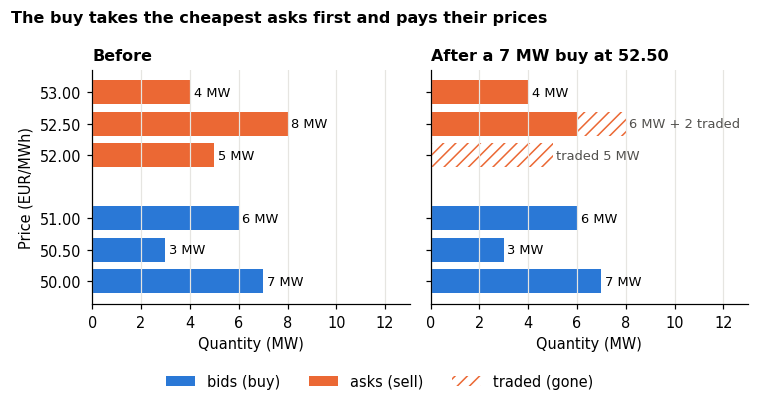

In [9]:
fig, axes = plt.subplots(1, 2, sharey=True, sharex=True, figsize=(7, 3.6))
traded = {p: q - dict(book_after[1]).get(p, 0.0) for p, q in book_before[1]}  # per ask level
for ax, (bids, asks), title in zip(axes, (book_before, book_after), ("Before", "After a 7 MW buy at 52.50")):
    for levels, col, name in ((bids, BUY, "bids (buy)"), (asks, SELL, "asks (sell)")):
        ax.barh([p for p, _ in levels], [q for _, q in levels], height=0.38, color=col, label=name)
        for p, q in levels:
            if ax is axes[0] or not traded.get(p) or col == BUY:
                ax.text(q + 0.15, p, f"{q:g} MW", va="center", fontsize=8.5)
    ax.set_title(title); ax.set_xlabel("Quantity (MW)"); ax.grid(axis="y", visible=False)
left = dict(book_after[1])
for p, q in traded.items():
    if q > 0:
        axes[1].barh(p, q, left=left.get(p, 0.0), height=0.38, fill=False, hatch="///", edgecolor=SELL,
                     lw=0, label="traded (gone)" if p == min(traded) else None)
        note = f"traded {q:g} MW" if p not in left else f"{left[p]:g} MW + {q:g} traded"
        axes[1].text(left.get(p, 0.0) + q + 0.15, p, note, va="center", fontsize=8.5, color="#52514e")
prices = sorted({p for side in book_before for p, _ in side})
axes[0].set_yticks(prices, [f"{p:.2f}" for p in prices]); axes[0].set_ylabel("Price (EUR/MWh)")
axes[0].set_xlim(0, 13); axes[0].set_xticks(range(0, 13, 2))
fig.suptitle("The buy takes the cheapest asks first and pays their prices", x=0.01, ha="left",
             fontsize=10.5, fontweight="bold")
fig.legend(*axes[1].get_legend_handles_labels(), loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## 4. How the book stores numbers: ticks

Prices move in steps of 0.01 EUR/MWh and quantities in steps of 0.1 MW. These smallest steps are
called **ticks**. Inside the engine, every price and quantity is a whole number of ticks. Whole
numbers add and compare exactly on any device, so matching does not depend on floating-point rounding:
the same inputs give the same matches.

> **Concept — integer tick encoding.** A price $p$ is stored as $n_p = \operatorname{round}\big((p - p_{\min}) / \Delta p\big)$, with
> the lowest allowed price $p_{\min} = -9{,}999$ EUR/MWh and the tick $\Delta p = 0.01$ EUR/MWh. The offset
> keeps negative prices positive. A quantity $q$ is stored as $n_q = \operatorname{round}(q / \Delta q)$, with $\Delta q = 0.1$ MW.
> A price or quantity between two ticks is rounded to the nearest tick.

You never need these numbers: every public call takes and returns EUR/MWh and MW. This is the only
cell of the tutorial that prints raw ticks, to show the encoding.

In [10]:
from omiecid_simulator.omiecid.encoding import decode_price, encode_price, encode_qty
from omiecid_simulator.omiecid.omie_config import OMIEProductConfig

cfg = OMIEProductConfig()  # the default product limits and ticks
print(f"price tick {cfg.price_tick} EUR/MWh, quantity tick {cfg.qty_tick} MW, "
      f"prices from {cfg.price_min:,.0f} to {cfg.price_max:,.0f} EUR/MWh")
for price in (52.00, 52.50, -5.00):
    print(f"   {price:6.2f} EUR/MWh -> {encode_price(price, cfg):>9,} ticks")
print(f"   5.0 MW -> {encode_qty(5.0, cfg)} ticks;  1,005,100 ticks -> {decode_price(1_005_100, cfg):.2f} EUR/MWh")

price tick 0.01 EUR/MWh, quantity tick 0.1 MW, prices from -9,999 to 9,999 EUR/MWh
    52.00 EUR/MWh -> 1,005,100 ticks
    52.50 EUR/MWh -> 1,005,150 ticks
    -5.00 EUR/MWh ->   999,400 ticks
   5.0 MW -> 50 ticks;  1,005,100 ticks -> 52.00 EUR/MWh


## Recap

- A contract is one 15-minute delivery period. It trades continuously until its gate closure, one hour before the start of its delivery hour.
- The order book holds resting bids and asks. The best bid and best ask frame the spread.
- An order that crosses the book trades at once, best price first, and at the passive order's price.
- `ContractBook.submit_order` returns a new book and a `SubmitResult`; `get_anonymous_lob` shows the book without names.
- Inside the engine, prices and quantities are whole numbers of ticks; the API speaks EUR/MWh and MW.

## Exercises

1. **A buy larger than the book.** Start from an empty book (`book.init()`), submit the same six
   resting orders, and send a buy of 20 MW at 53.00 EUR/MWh. How much trades, at what average
   price, and what happens to the rest?
   *Hint:* add up the asks at or below 53.00. A limit order that is not fully filled keeps its
   remainder in the book (see [T02](T02_order_types.ipynb)).
2. **A sell that crosses.** On the book after the buy, send a sell of 8 MW at 50.50 EUR/MWh. Which
   bids does it hit, and which prices does the seller receive?
   *Hint:* for a sell, the best price is the highest bid.

The solutions are in the collapsed cell at the end.

## Further reading

- [The market model](../docs/market-model.md): contracts, gate closure, price-time priority, units and ticks. [The modelling assumptions](../docs/modelling-assumptions.md): what the simulator interprets or simplifies.
- [Sessions](../docs/sessions.md): the same market on a clock, with the order flow of a whole trading day.
- The evidence: [the market specification](../docs/omiecid/market-spec.md) and [the certificate](../docs/omiecid/certificate.md). Scenario [C02](../notebooks/certification/C02_single_crossing_pair.ipynb) certifies a single crossing pair, and [C06](../notebooks/certification/C06_multi_level_walk_vwap.ipynb) the walk over several price levels.
- Next tutorial: [T02 — Order types and matching](T02_order_types.ipynb).

## Solutions

In [11]:
# Solutions to the exercises (collapsed; expand to read).
# 1. Rebuild the six resting orders, then send a 20 MW buy at 53.00 EUR/MWh.
s = book.init()
for seller, (price, qty) in zip((11, 12, 13), [(52.00, 5), (52.50, 8), (53.00, 4)]):
    s, _ = submit(s, Side.SELL, price, qty, agent_id=seller)
for buyer, (price, qty) in zip((21, 22, 23), [(51.00, 6), (50.50, 3), (50.00, 7)]):
    s, _ = submit(s, Side.BUY, price, qty, agent_id=buyer)
s, r = submit(s, Side.BUY, 53.00, 20, agent_id=2)
print(f"1. traded {float(r.trade_qty):.1f} MW at an average of {float(r.trade_price):.2f} EUR/MWh")
show_book(s)  # every ask is gone (5 + 8 + 4 = 17 MW); the other 3 MW rest as a new bid at 53.00

# 2. On the book after the 7 MW buy, a sell of 8 MW at 50.50 hits 6 MW at 51.00, then 2 MW at 50.50.
s, r = submit(state, Side.SELL, 50.50, 8, agent_id=3)
print("2.", [(f"{p:.2f} EUR/MWh", f"{q:.1f} MW") for p, q, _ in book.get_agent_trades(s, 3)])
show_book(s)

1. traded 17.0 MW at an average of 52.47 EUR/MWh
   -------------------------------
   bid   53.00 EUR/MWh   3.0 MW
   bid   51.00 EUR/MWh   6.0 MW
   bid   50.50 EUR/MWh   3.0 MW
   bid   50.00 EUR/MWh   7.0 MW
2. [('51.00 EUR/MWh', '6.0 MW'), ('50.50 EUR/MWh', '2.0 MW')]
   ask   53.00 EUR/MWh   4.0 MW
   ask   52.50 EUR/MWh   6.0 MW
   -------------------------------
   bid   50.50 EUR/MWh   1.0 MW
   bid   50.00 EUR/MWh   7.0 MW
